### 이진 분류 실습 문제 1

## Iris Dataset
: 붓꽃의 꽃받침과 꽃잎의 측정값을 이용해 Setosa와 Versicolor 두 품종을 구분하는 이진 분류 모델 구현.

- 전체 데이터: 150개
- 이번 실습에서 사용할 데이터: 100개
- 입력 특징: 4개
- 정답: 꽃 품종 (Setosa 또는 Versicolor)

| 열 이름 | 의미 | 설명 |
|:---:|:---:|:---|
| `sepal_length` | 꽃받침 길이 | 꽃받침의 길이, cm |
| `sepal_width` | 꽃받침 너비 | 꽃받침의 너비, cm |
| `petal_length` | 꽃잎 길이 | 꽃잎의 길이, cm |
| `petal_width` | 꽃잎 너비 | 꽃잎의 너비, cm |
| `species` | 꽃 품종 | `setosa`, `versicolor`, `virginica` |


#### Step1. 데이터 불러오기 및 전처리

**실습 조건**
- `setosa`와 `versicolor` 두 품종만 사용하고 `virginica`는 제외한다.
- `setosa`는 클래스 0, `versicolor`는 클래스 1로 변환한다.
- 4개의 측정값을 입력값(X), 품종 레이블을 정답(y)으로 사용한다.
- 학습 데이터와 테스트 데이터를 8:2 비율로 분리한다.
- 학습 데이터의 평균과 표준편차를 이용해 입력 특징을 표준화한다.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

import torch
from torch import nn, optim
from torch.utils.data import TensorDataset, DataLoader

from sklearn.model_selection import train_test_split
from sklearn.metrics import *
from sklearn.preprocessing import StandardScaler, MinMaxScaler

In [2]:
url = "https://raw.githubusercontent.com/mwaskom/seaborn-data/master/iris.csv"
columns = ['sepal_length','sepal_width', 'petal_length', 'petal_width', 'species']
df = pd.read_csv(url,names=columns)
# Setosa와 Versicolor만 선택, virginica 제외
df = df[df["species"].isin(["setosa", "versicolor"])].copy()
print(df.head())

# x 와 y 로 분리
x = df.drop('species', axis=1)
# class 0 과 class 1로 변환
y = df['species'].map({'setosa':0, 'versicolor':1}).values  # Numpy 배열 변환(for CPU 연산)

# CPU 사용 확인
device = 'cuda' if torch.cuda.is_available() else 'cpu'
print(f'Using {device}')

# 8:2 로 분리
x_train, x_val, y_train, y_val = train_test_split(x, y, test_size=0.2, random_state= 42)

# 입력 특징의 표준화 | Scaler
scaler = MinMaxScaler()
x_train = scaler.fit_transform(x_train)
x_val = scaler.transform(x_val)

# print('x_train :', x_train.shape)
# print('y_train :', y_train.shape)
# print('x_val :', x_val.shape)
# print('y_val :', y_val.shape)

  sepal_length sepal_width petal_length petal_width species
1          5.1         3.5          1.4         0.2  setosa
2          4.9         3.0          1.4         0.2  setosa
3          4.7         3.2          1.3         0.2  setosa
4          4.6         3.1          1.5         0.2  setosa
5          5.0         3.6          1.4         0.2  setosa
Using cpu


In [3]:
# make_DataSet 함수 생성
def make_DataSet(x_train, x_val, y_train, y_val, batch_size= 32):
    x_train_ts = torch.tensor(x_train, dtype= torch.float32)
    y_train_ts = torch.tensor(y_train, dtype= torch.float32).view(-1,1)
    x_val_ts = torch.tensor(x_val, dtype= torch.float32)
    y_val_ts = torch.tensor(y_val, dtype= torch.float32).view(-1,1)

    # TensorDataSet 생성    
    train_dataset = TensorDataset(x_train_ts, y_train_ts)

    # DataLoader 생성
    train_loader = DataLoader(train_dataset, batch_size= batch_size, shuffle= True)
    return train_loader, x_val_ts, y_val_ts

In [4]:
# 데이터 로더 구성 by make_DataSet
train_loader, x_val_ts, y_val_ts = make_DataSet(x_train, x_val, y_train, y_val, 32)

#### Step2. 모델 만들기

**목표:** Banknote Authentication 실습에서 사용한 MLP 구조로 붓꽃 품종을 분류한다.

- 입력 노드: 4개
- 은닉층: 100개 노드
- 출력 노드: 1개
- 출력 활성화 함수: Sigmoid
- 예측값이 0.5 이상이면 클래스 1, 0.5 미만이면 클래스 0

In [5]:
class MLP(nn.Module):
    def __init__(self):
        super().__init__()

        self.linear = nn.Sequential(nn.Linear(4,100),
                                nn.Sigmoid(),
                                nn.Linear(100,1),
                                nn.Sigmoid()
                                )

    def forward(self, x):
        x = self.linear(x)
        return x

model = MLP()

#### STEP 3. 모델 학습시키기

- Optimizer: SGD
- Loss function: BCELoss
- 학습률(LR): 0.1
- Epoch: 100
- Batch size: 16 또는 32

In [ ]:
LR = 1e-1
EPOCH = 100

N = len(train_loader.dataset)

optimizer = optim.SGD(model.parameters(), lr = LR)
criterion = nn.BCELoss()

loss_history = []

model.train()
for ep in range(EPOCH):
    rloss = 0
    for x_batch, y_batch in train_loader:
        y_hat = model(x_batch)
        loss = criterion(y_hat, y_batch) 

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        rloss += loss.item() * x_batch.shape[0]

    epoch_loss = rloss / N
    loss_history.append(epoch_loss)

    if ep % 33 == 0:
        print(f'Epoch: {ep+1}, loss: {epoch_loss:.4f}')

Epoch: 1, loss: 0.6924
Epoch: 34, loss: 0.3986
Epoch: 67, loss: 0.2143
Epoch: 100, loss: 0.1243


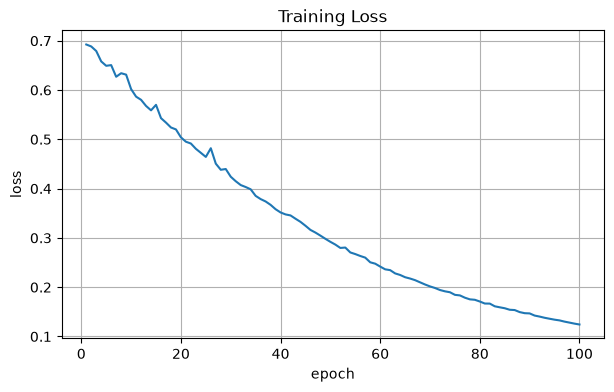

In [7]:
plt.figure(figsize= (7,4))
plt.plot(range(1, EPOCH + 1), loss_history)
plt.xlabel('epoch')
plt.ylabel('loss')
plt.title('Training Loss')
plt.grid()

#### Step4. 모델 테스트하기

- Sigmoid 출력값에 임계값 0.5를 적용해 클래스를 예측.
- 전체 테스트 데이터 중 정답을 맞힌 개수와 Accuracy(%)를 출력.

#### Step5. 테스트 결과 시각화

- 실제 클래스와 예측 클래스를 이용해 2×2 혼동행렬(Confusion Matrix)을 작성.
- 실제 클래스별 예측 확률 분포를 히스토그램으로 나타내시오.
- 혼동행렬의 행은 실제 클래스, 열은 예측 클래스로 표시하시오.
- 클래스 0과 클래스 1이 무엇을 의미하는지 그래프에 표시하시오.

#### STEP 6. 파라미터 개수 확인